# 01 · Exploratory Data Analysis

Goal: understand the weekly product panel before estimating any elasticity.

Questions:
1. What do prices and quantities look like?
2. Do prices actually change within a product? (Without price changes there is nothing to estimate.)
3. How strong is seasonality, and does price move with it? (If it does, season is a confounder.)
4. What does the raw price-demand relationship look like, and how does it change once we compare a product only with itself?

Data: `weekly_sales` table built by `python -m econocausal.data.build`.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from econocausal.data.db import load_panel, get_engine, read_table
from econocausal.viz import BLUE, ORANGE, GREY, TEXT_MUTED, save_figure, set_style

set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

panel = load_panel().sort_values(["stock_code", "week_start"]).reset_index(drop=True)
panel.head()

,stock_code,week_start,description,price,quantity,revenue,n_invoices,n_customers,uk_share,guest_share,log_price,log_quantity,year,month,week_of_year,weeks_to_christmas,is_peak_season,has_bank_holiday,category
0,10002,2009-11-30,INFLATABLE POLITICAL GLOBE,0.850,140,119.000,10,10,0.800,0.000,-0.163,4.942,2009,11,49,3,1,0,other
1,10002,2009-12-07,INFLATABLE POLITICAL GLOBE,0.850,24,21.250,4,3,0.750,0.250,-0.163,3.178,2009,12,50,2,0,0,other
2,10002,2009-12-14,INFLATABLE POLITICAL GLOBE,0.850,37,32.300,3,2,1.000,0.333,-0.163,3.611,2009,12,51,1,0,0,other
3,10002,2009-12-21,INFLATABLE POLITICAL GLOBE,0.850,14,12.750,3,2,1.000,0.333,-0.163,2.639,2009,12,52,0,0,1,other
4,10002,2010-01-04,INFLATABLE POLITICAL GLOBE,0.850,15,12.750,2,2,1.000,0.000,-0.163,2.708,2010,1,1,50,0,0,other


## 1. Overview

In [2]:
overview = pd.Series({
    "rows (product-weeks)": len(panel),
    "products": panel["stock_code"].nunique(),
    "weeks": panel["week_start"].nunique(),
    "first week": panel["week_start"].min().date(),
    "last week": panel["week_start"].max().date(),
    "total units": panel["quantity"].sum(),
    "total revenue (GBP)": round(panel["revenue"].sum()),
})
overview.to_frame("value")

,value
rows (product-weeks),126672
products,1877
weeks,103
first week,2009-11-30
last week,2011-11-28
total units,5796333
total revenue (GBP),10346165


In [3]:
read_table("cleaning_log", get_engine())

,step,rows_removed,rows_left
0,drop_cancellations,19500,1047871
1,drop_non_positive,6202,1041669
2,keep_product_codes,4792,1036877
3,drop_duplicates,33663,1003214
4,drop_price_outliers,882,1002332
5,drop_bulk_outliers,101,1002231


## 2. Distributions of price and quantity

Both are strongly right-skewed: most products are cheap and sell a few units a week, a few sell
hundreds. On a log scale both look much closer to normal, which is one reason the demand model
uses `log(quantity)` and `log(price)`.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


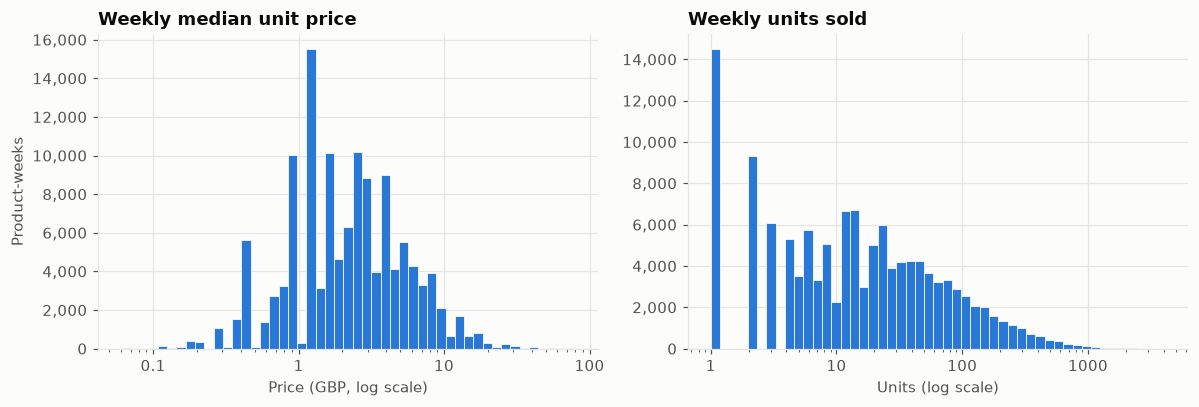

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

bins = np.logspace(np.log10(panel["price"].min()), np.log10(panel["price"].max()), 50)
axes[0].hist(panel["price"], bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set_xscale("log")
axes[0].set_title("Weekly median unit price")
axes[0].set_xlabel("Price (GBP, log scale)")
axes[0].set_ylabel("Product-weeks")

bins = np.logspace(0, np.log10(panel["quantity"].max()), 50)
axes[1].hist(panel["quantity"], bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set_xscale("log")
axes[1].set_title("Weekly units sold")
axes[1].set_xlabel("Units (log scale)")

for ax in axes:
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}"))
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

fig.tight_layout()
save_figure(fig, "01_price_quantity_distributions")

In [5]:
panel[["price", "quantity", "revenue", "n_invoices", "n_customers"]].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95]
).T

,count,mean,std,min,25%,50%,75%,95%,max
price,"126,672.000",3.199,3.711,0.060,1.250,2.100,3.755,9.645,79.950
quantity,"126,672.000",45.759,107.139,1.000,4.000,13.000,42.000,193.000,"4,115.000"
revenue,"126,672.000",81.677,198.998,0.100,10.080,26.900,76.050,319.819,"9,461.550"
n_invoices,"126,672.000",4.610,5.223,1.000,1.000,3.000,6.000,14.000,101.000
n_customers,"126,672.000",3.321,4.225,0.000,1.000,2.000,4.000,11.000,90.000


## 3. Price variation within products

DML estimates the elasticity from how quantity responds when a product's own price changes.
So the important variation is **within** a product over time, not between cheap and expensive products.

In [6]:
by_product = panel.groupby("stock_code")
within_dev = panel["log_price"] - by_product["log_price"].transform("mean")

price_sd = by_product["log_price"].std()
changed = by_product["price"].diff().abs() > 0.005
has_previous = by_product["price"].diff().notna()

variation = pd.Series({
    "share of log-price variance that is within products": within_dev.var() / panel["log_price"].var(),
    "median within-product SD of log price": price_sd.median(),
    "products with SD of log price > 0.15": (price_sd > 0.15).mean(),
    "share of weeks where price changed vs previous sale week": changed[has_previous].mean(),
})
variation.to_frame("value")

,value
share of log-price variance that is within products,0.133
median within-product SD of log price,0.276
products with SD of log price > 0.15,0.902
share of weeks where price changed vs previous sale week,0.368


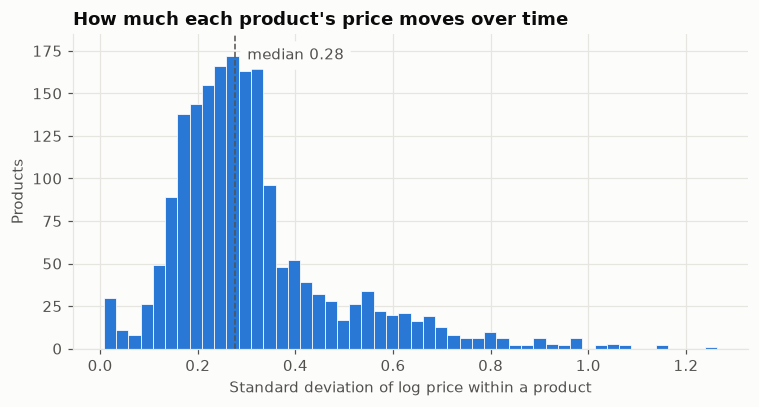

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(price_sd, bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(price_sd.median(), color=TEXT_MUTED, linewidth=1, linestyle="--")
ax.annotate(f"median {price_sd.median():.2f}", xy=(price_sd.median(), ax.get_ylim()[1] * 0.92),
            xytext=(8, 0), textcoords="offset points", color=TEXT_MUTED,
            backgroundcolor="#fcfcfb")
ax.set_title("How much each product's price moves over time")
ax.set_xlabel("Standard deviation of log price within a product")
ax.set_ylabel("Products")
fig.tight_layout()
save_figure(fig, "02_within_product_price_variation")

Price paths for four of the best-selling products. Prices move in steps (list price changes)
plus week-to-week noise from discounts and the mix of customers buying.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


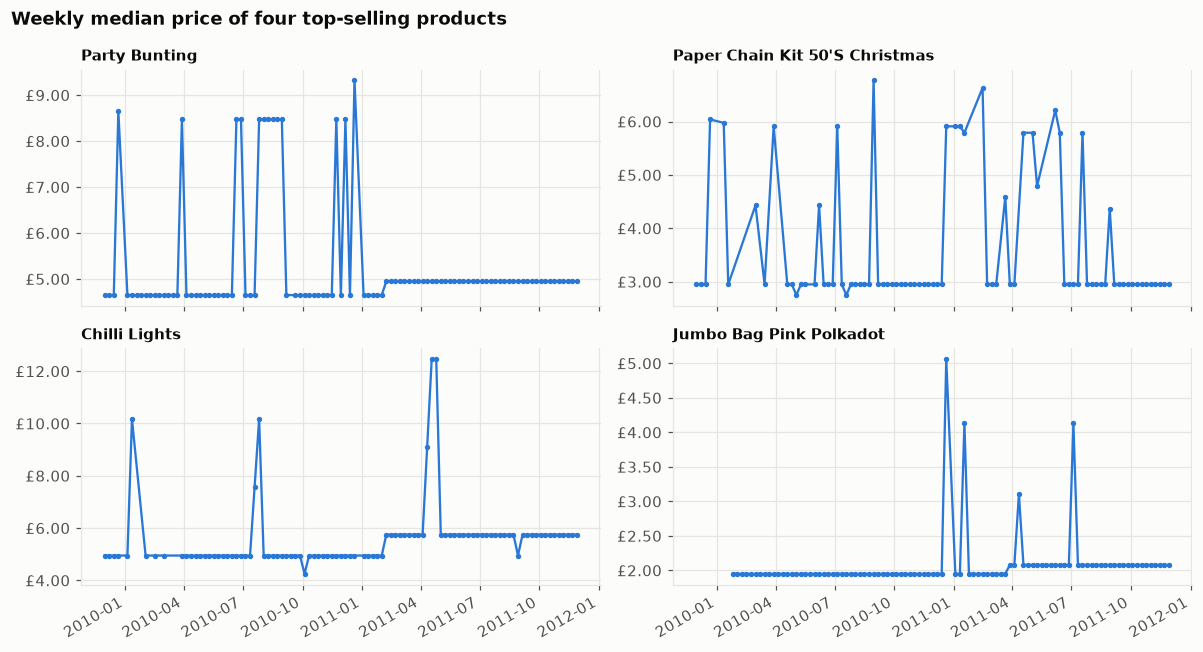

In [8]:
top = panel.groupby(["stock_code", "description"])["revenue"].sum().nlargest(4).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, (_, row) in zip(axes.flat, top.iterrows()):
    d = panel[panel["stock_code"] == row["stock_code"]]
    ax.plot(d["week_start"], d["price"], color=BLUE, linewidth=1.5, marker="o", markersize=2.5)
    ax.set_title(row["description"].title(), fontsize=10)
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("£{x:.2f}"))
fig.suptitle("Weekly median price of four top-selling products", x=0.01, ha="left",
             fontweight="semibold")
fig.autofmt_xdate()
fig.tight_layout()
save_figure(fig, "03_example_price_paths")

## 4. Seasonality

Total units sold per week across all products in the panel. The panel only contains weeks in which a
product sold, so this is a demand indicator rather than exact shop totals.

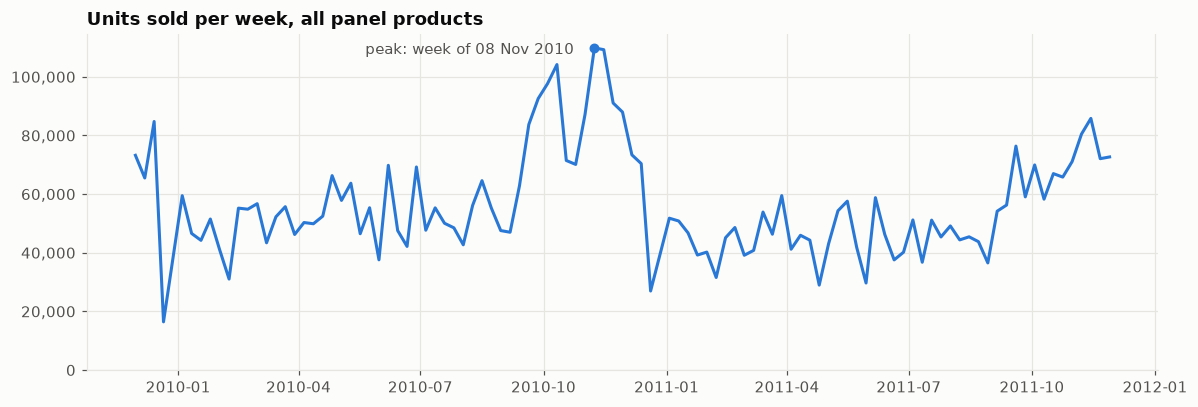

In [9]:
weekly_total = panel.groupby("week_start").agg(
    units=("quantity", "sum"), revenue=("revenue", "sum"), products_sold=("stock_code", "size")
)
peak = weekly_total["units"].idxmax()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(weekly_total.index, weekly_total["units"], color=BLUE)
ax.scatter([peak], [weekly_total.loc[peak, "units"]], color=BLUE, s=30, zorder=3)
ax.annotate(f"peak: week of {peak:%d %b %Y}", xy=(peak, weekly_total.loc[peak, "units"]),
            xytext=(-150, -4), textcoords="offset points", color=TEXT_MUTED)
ax.set_title("Units sold per week, all panel products")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(0)
fig.tight_layout()
save_figure(fig, "04_weekly_units_over_time")

Does **price** move with the season too? To remove differences between products, both price and
quantity are measured as the deviation from the product's own average (in log points, roughly %).

,quantity_dev,price_dev
month,,
1,-0.000,0.018
2,-0.127,0.032
3,-0.003,0.027
4,-0.089,0.004
5,-0.110,0.004
6,-0.116,-0.012
7,-0.122,-0.040
8,-0.142,-0.026
9,0.048,-0.044


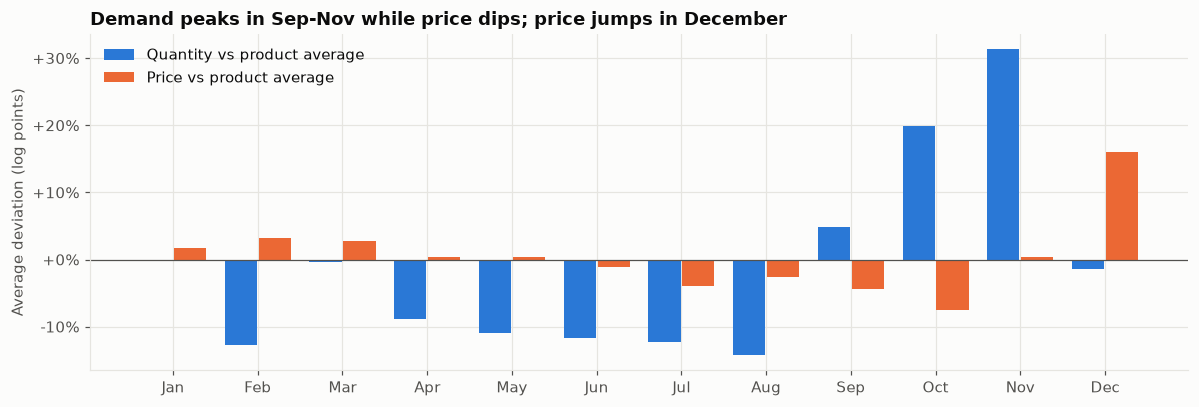

In [10]:
dev = panel.assign(
    price_dev=panel["log_price"] - by_product["log_price"].transform("mean"),
    quantity_dev=panel["log_quantity"] - by_product["log_quantity"].transform("mean"),
)
monthly = dev.groupby("month")[["quantity_dev", "price_dev"]].mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(12)
ax.bar(x - 0.2, monthly["quantity_dev"], width=0.38, color=BLUE, label="Quantity vs product average")
ax.bar(x + 0.2, monthly["price_dev"], width=0.38, color=ORANGE, label="Price vs product average")
ax.axhline(0, color=TEXT_MUTED, linewidth=0.8)
ax.set_xticks(x, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_ylabel("Average deviation (log points)")
ax.set_title("Demand peaks in Sep-Nov while price dips; price jumps in December")
ax.legend(loc="upper left")
fig.tight_layout()
save_figure(fig, "05_monthly_quantity_vs_price")
monthly

## 5. Customer mix and price

Order lines without a customer ID are one-off buyers. They pay a higher retail price tier,
about 2x the product's usual (wholesale) price. Because the weekly price is a median over order
lines, the price of a product-week jumps to the retail tier once guests make up about half of its
lines. Weeks bought **only** by guests (13% of product-weeks) also sell far fewer units, because
guests buy small quantities. So `guest_share` moves both price and quantity: it is a confounder.

Most product-weeks are at the extremes (44% have no guest lines, 13% are all guests), so the
middle bins are smaller and noisier. Mixed weeks tend to be busy weeks with many orders.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Correlation of guest share with within-product price: 0.51


,price_dev,quantity_dev,rows
guest_share,,,
"(-0.001, 0.1]",-0.118,0.010,58132
"(0.1, 0.2]",-0.109,0.688,11045
"(0.2, 0.3]",-0.119,0.550,8934
"(0.3, 0.4]",-0.127,0.337,10813
"(0.4, 0.5]",0.176,-0.008,12556
"(0.5, 0.6]",0.369,0.428,1963
"(0.6, 0.7]",0.364,0.075,3548
"(0.7, 0.8]",0.268,0.251,2184
"(0.8, 0.9]",0.063,0.753,740


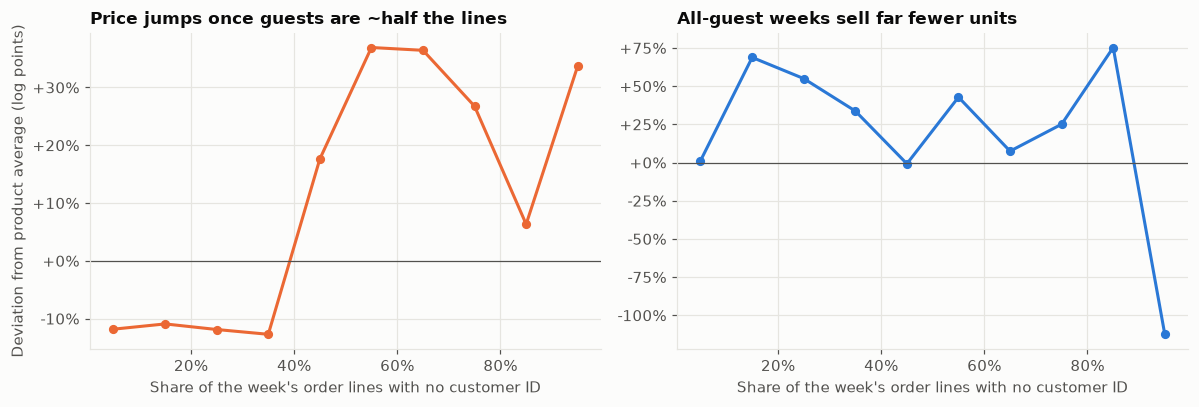

In [11]:
dev["guest_share"] = panel["guest_share"]
bins = pd.cut(dev["guest_share"], bins=np.linspace(0, 1, 11), include_lowest=True)
by_guest = dev.groupby(bins, observed=True).agg(
    price_dev=("price_dev", "mean"), quantity_dev=("quantity_dev", "mean"), rows=("price_dev", "size")
)
mid = [b.mid for b in by_guest.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
axes[0].plot(mid, by_guest["price_dev"], color=ORANGE, marker="o", markersize=5)
axes[0].set_title("Price jumps once guests are ~half the lines", fontsize=11)
axes[1].plot(mid, by_guest["quantity_dev"], color=BLUE, marker="o", markersize=5)
axes[1].set_title("All-guest weeks sell far fewer units", fontsize=11)
for ax in axes:
    ax.axhline(0, color=TEXT_MUTED, linewidth=0.8)
    ax.set_xlabel("Share of the week's order lines with no customer ID")
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0%}"))
axes[0].set_ylabel("Deviation from product average (log points)")
fig.tight_layout()
save_figure(fig, "06_guest_share_price_quantity")
print(f"Correlation of guest share with within-product price: "
      f"{dev['guest_share'].corr(dev['price_dev']):.2f}")
by_guest

## 6. Demand curves: raw vs within-product

**Left:** all product-weeks pooled. The slope mixes up differences *between* products (cheap
products sell more units) with the effect of a product's own price.
**Right:** each product compared only with itself (deviations from its own average), shown as a
binned scatter (20 equal-size bins).

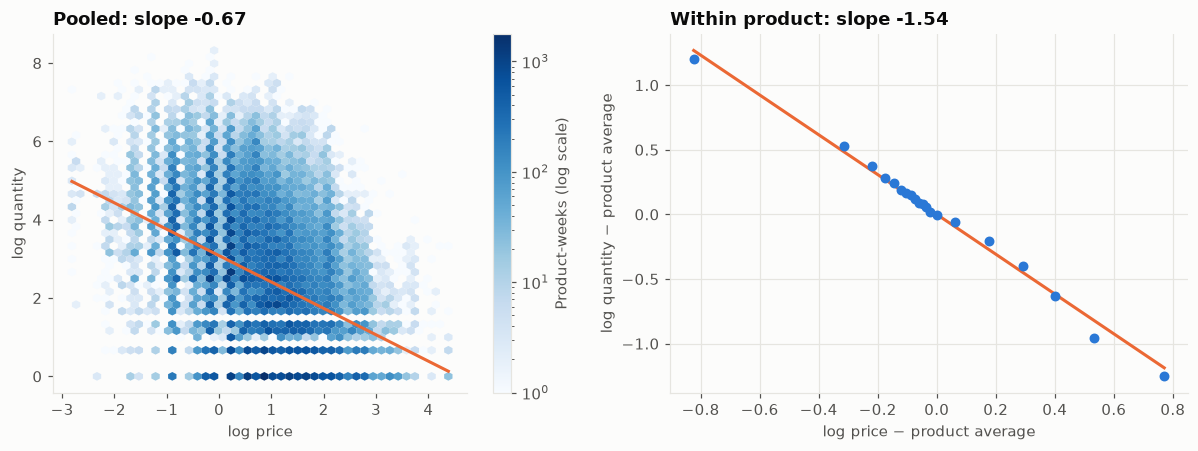

In [12]:
pooled_slope, pooled_icept = np.polyfit(panel["log_price"], panel["log_quantity"], 1)
within_slope, _ = np.polyfit(dev["price_dev"], dev["quantity_dev"], 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

hb = axes[0].hexbin(panel["log_price"], panel["log_quantity"], gridsize=45, cmap="Blues",
                    mincnt=1, bins="log", linewidths=0)
xs = np.linspace(panel["log_price"].min(), panel["log_price"].max(), 50)
axes[0].plot(xs, pooled_icept + pooled_slope * xs, color=ORANGE)
axes[0].set_title(f"Pooled: slope {pooled_slope:.2f}")
axes[0].set_xlabel("log price")
axes[0].set_ylabel("log quantity")
axes[0].grid(False)
fig.colorbar(hb, ax=axes[0], label="Product-weeks (log scale)")

qbins = pd.qcut(dev["price_dev"], 20, duplicates="drop")
binned = dev.groupby(qbins, observed=True)[["price_dev", "quantity_dev"]].mean()
axes[1].scatter(binned["price_dev"], binned["quantity_dev"], color=BLUE, s=30, zorder=3)
xs = np.linspace(binned["price_dev"].min(), binned["price_dev"].max(), 50)
axes[1].plot(xs, within_slope * xs, color=ORANGE)
axes[1].set_title(f"Within product: slope {within_slope:.2f}")
axes[1].set_xlabel("log price − product average")
axes[1].set_ylabel("log quantity − product average")

fig.tight_layout()
save_figure(fig, "07_demand_curves_pooled_vs_within")

How the naive slope changes as more confounders are controlled for. These are plain OLS
regressions, **not** causal estimates; they show how sensitive the answer is to what we control for,
which is the motivation for Double ML.

In [13]:
import statsmodels.formula.api as smf

week_dev = dev.assign(
    guest_dev=dev["guest_share"] - by_product["guest_share"].transform("mean"),
    week=panel["week_start"].astype(str),
)
specs = {
    "Pooled OLS (no controls)": smf.ols("log_quantity ~ log_price", data=panel),
    "Within product": smf.ols("quantity_dev ~ price_dev", data=week_dev),
    "Within product + week": smf.ols("quantity_dev ~ price_dev + C(week)", data=week_dev),
    "Within product + week + guest share": smf.ols(
        "quantity_dev ~ price_dev + C(week) + guest_dev", data=week_dev
    ),
}
rows = []
for name, model in specs.items():
    fit = model.fit()
    coef = fit.params.get("log_price", fit.params.get("price_dev"))
    rows.append({"specification": name, "price slope": coef})
slopes = pd.DataFrame(rows).set_index("specification")
slopes

,price slope
specification,
Pooled OLS (no controls),-0.674
Within product,-1.540
Within product + week,-1.594
Within product + week + guest share,-1.522


## 7. Categories

In [14]:
panel.groupby("category").agg(
    product_weeks=("quantity", "size"),
    products=("stock_code", "nunique"),
    median_price=("price", "median"),
    median_weekly_units=("quantity", "median"),
    median_guest_share=("guest_share", "median"),
).sort_values("product_weeks", ascending=False)

,product_weeks,products,median_price,median_weekly_units,median_guest_share
category,,,,,
other,47047,699,2.460,11.000,0.143
kitchen_dining,19211,258,2.550,16.000,0.182
home_decor,16578,249,2.100,15.000,0.167
stationery_cards,12069,168,1.240,24.000,0.176
candles_lighting,10085,157,2.370,12.000,0.000
bags,7330,94,2.100,24.000,0.200
toys_kids,4289,59,2.100,16.000,0.000
jewellery,3418,71,3.750,2.000,0.750
christmas,2812,60,1.370,31.500,0.182


## Summary

The written findings are in [`docs/eda_findings.md`](../docs/eda_findings.md).